# ML and fairness tests with a measured size and power, a permutation reference for shift and a Beta-Binomial coverage null


**Question:** How often do the machine-learning and fairness tests fire when nothing is wrong and how often when a defect is planted, and do the corrections made to the coverage, shift and situation tests change those rates?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 02, 04 and 07 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- define the **size** (the rejection rate when nothing is wrong) and the **power** (the rejection rate against a planted defect) of a validation test, and give each with its Monte Carlo standard error;
- measure the size of the split-conformal coverage test under a binomial null and under the Beta-Binomial null the engine uses, at three ratios of test window to calibration window;
- measure how often a fixed AUC-drop rule fires on the worst subsample when there is no shift, and compare it with the permutation reference of the engine, in size and power;
- measure the size and the power of the situation-testing light at the two amber cut points;
- see the corrected tests in the committed rows of cases C20 and C21, and say what this evidence supports and what it does not.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import plants as fair_plants
from riskvalidation.fairness import situation
from riskvalidation.ml import conformal, plants, robustness

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
YN = {True: "yes", False: "no"}

riskvalidation 1.1.0
numpy 2.4.6
matplotlib 3.11.2


## Data

- **Simulated null and planted-defect data from the engine's own generators**: exchangeable scores for the coverage test, `CovariateShiftPlant` (shift 0 is the null, shift 2 plants a shift) for the resilience test and `ThresholdBiasPlant` (gap 0 is the null, gap 0.8 a planted bias) for the situation test. Synthetic, seeded, no licence class. Every simulation is small enough to run in under two minutes in this notebook; larger runs belong to the engine's own size-and-power suites.
- **Two committed documents** that carry the corrected tests in use (owner: this repository): `data/derived/C20/fed-shift.json` (a LightGBM model on the UCI Polish bankruptcy data, CC BY 4.0, class mirror-allowed, under synthetic shifts sized by the Federal Reserve's corporate portfolios; its conformal rows hold both p-values and its resilience row its 199 permutation draws) and `data/derived/C21/pair-2018-19.json` (the HMDA comparison of Delaware, its situation-testing row with the amber cut point it uses). The first cell of the Method opens them and prints the engine version that baked them.

In [2]:
# Open the two committed documents and print the engine version that baked each
fed_path = ROOT / "data" / "derived" / "C20" / "fed-shift.json"
hmda_path = ROOT / "data" / "derived" / "C21" / "pair-2018-19.json"
fed = json.loads(fed_path.read_text(encoding="utf-8"))
hmda = json.loads(hmda_path.read_text(encoding="utf-8"))
print("C20 fed-shift baked with riskvalidation", fed["provenance"]["riskvalidation_version"], end=" ")
print("| C21 pair-2018-19", hmda["provenance"]["riskvalidation_version"])

C20 fed-shift baked with riskvalidation 1.1.0 | C21 pair-2018-19 1.1.0


## Method

A validation test is a decision rule, and a decision rule has error rates. For a test that rejects at level $\alpha = 0.05$:

$$\text{size} = P(\text{reject} \mid \text{nothing is wrong}), \qquad \text{power} = P(\text{reject} \mid \text{a defect of known severity}).$$

A test with a size above its nominal level raises false alarms and teaches a team to ignore it; a test with low power misses what it was built to find. Both are properties of the rule and of the sample sizes, and neither is stated by the dossier's description of the tests. Over $R$ independent simulations the rejection rate $\hat{r}$ has the Monte Carlo standard error $\sqrt{\hat{r}(1-\hat{r})/R}$, which the cells print beside every rate. Every random draw is seeded.

### Step 1: the size of the coverage test, binomial against Beta-Binomial

With exchangeable scores the true coverage given the calibration window is $\mathrm{Beta}(k, n_{\mathrm{cal}}+1-k)$ (notebook 04). A test that compares the covered count $c$ of $m$ test points with $\mathrm{Binomial}(m, 1-\alpha)$ treats the coverage as the fixed number $1-\alpha$ and ignores that variation; the variation is small when $m \ll n_{\mathrm{cal}}$ and large when it is not. The approximate size of the binomial test is

$$\text{size}_{\text{binomial}} \approx 2\Bigl(1 - \Phi\bigl(1.96 / \sqrt{1 + m/n_{\mathrm{cal}}}\bigr)\Bigr),$$

with $\Phi$ the standard normal distribution function: 5% as $m/n_{\mathrm{cal}} \to 0$ and above it otherwise. The engine returns both p-values; the next cell draws 1,500 exchangeable replications at each of three ratios of $m$ to $n_{\mathrm{cal}}$ (0.1, 1 and 4) and counts how often each p-value is below 0.05.

Before the simulation, one replication shows what it repeats. The next cell draws the calibration scores and the test
scores of one exchangeable window, takes the conformal quantile, counts the covered test points and prints both
p-values.

In [3]:
# One exchangeable replication: the quantile, the covered count and both p-values
demo = np.random.default_rng(7)
n_cal, m = 2000, 2000
q = conformal.split_conformal_quantile(demo.random(n_cal), 0.1)
covered = demo.random(m) <= q
sets = np.column_stack([covered, np.zeros(m, dtype=bool)])
result = conformal.conformal_coverage(sets, np.zeros(m, dtype=int), 0.1, n_cal=n_cal)
print(f"quantile {q:.4f} | coverage {result.coverage:.4f} | k {result.k} | target {result.target:.2f}")
print(f"p Beta-Binomial {result.p_value:.4f} | p binomial {result.p_value_binomial:.4f}")

quantile 0.8974 | coverage 0.8945 | k 1801 | target 0.90
p Beta-Binomial 0.5264 | p binomial 0.4122


The cell below repeats that replication 1,500 times for each of the three window ratios.

In [4]:
# Size of the coverage test under exchangeability: how often each p-value falls below 0.05
rng = np.random.default_rng(1)
REPS = 1500
conformal_size = {}
print(f"{'n_cal':>6s} {'m':>5s} {'m / n_cal':>9s} | {'binomial size':>16s} {'Monte Carlo se':>18s}", end=" ")
print(f"| {'Beta-Binomial size':>20s} {'Monte Carlo se':>18s}")
for n_cal, m in ((20000, 2000), (2000, 2000), (1000, 4000)):
    below_binomial = below_beta = 0
    for _ in range(REPS):
        q = conformal.split_conformal_quantile(rng.random(n_cal), 0.1)
        covered = rng.random(m) <= q
        sets = np.column_stack([covered, np.zeros(m, dtype=bool)])
        result = conformal.conformal_coverage(sets, np.zeros(m, dtype=int), 0.1, n_cal=n_cal)
        below_binomial += result.p_value_binomial < 0.05
        below_beta += result.p_value < 0.05
    sizes = (below_binomial / REPS, below_beta / REPS)
    conformal_size[(n_cal, m)] = sizes
    errors = [float(np.sqrt(s * (1 - s) / REPS)) for s in sizes]
    print(f"{n_cal:6d} {m:5d} {m / n_cal:9.1f} | {sizes[0]:16.4f} {errors[0]:18.4f}", end=" ")
    print(f"| {sizes[1]:20.4f} {errors[1]:18.4f}")

 n_cal     m m / n_cal |    binomial size     Monte Carlo se |   Beta-Binomial size     Monte Carlo se
 20000  2000       0.1 |           0.0600             0.0061 |               0.0460             0.0054
  2000  2000       1.0 |           0.1587             0.0094 |               0.0440             0.0053
  1000  4000       4.0 |           0.3893             0.0126 |               0.0427             0.0052


The three sizes of each test are easier to compare against the nominal level than as columns of numbers. The next cell
draws them, with the 0.05 line.

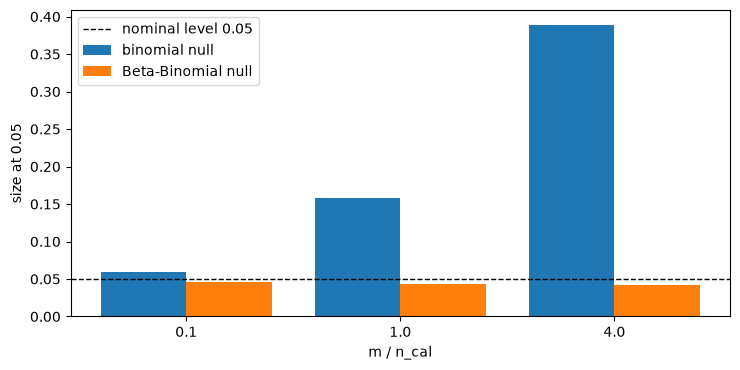

In [5]:
# Size of the coverage test by window ratio, under the binomial and under the Beta-Binomial null
ratios = [f"{m / n:.1f}" for n, m in conformal_size]
position = np.arange(len(ratios))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(position - 0.2, [s[0] for s in conformal_size.values()], width=0.4, label="binomial null")
ax.bar(position + 0.2, [s[1] for s in conformal_size.values()], width=0.4, label="Beta-Binomial null")
ax.axhline(0.05, color="black", linestyle="--", linewidth=1, label="nominal level 0.05")
ax.set_xticks(position)
ax.set_xticklabels(ratios)
ax.set_xlabel("m / n_cal")
ax.set_ylabel("size at 0.05")
ax.legend()
fig.tight_layout()
plt.show()

The binomial null rejects at 0.0600, 0.1587 and 0.3893 as the test window grows from a tenth of the calibration window
to four times it, which is the false-alarm rate a team would learn to ignore. The Beta-Binomial null stays at 0.0460,
0.0440 and 0.0427, under the dashed line at all three ratios and never above it. The binomial form is close to the right
size only when the test window is small against the calibration window, because it ignores that the calibration
quantile is itself random.

### Step 2: the resilience test, a fixed drop against a permutation reference

Notebook 02 showed that the AUC drop on the worst subsample by shift score is positive even where nothing moved, because that subsample is a region of the feature space and the AUC on a restricted range is lower. A rule that reads the drop against a **fixed** cut therefore fires on a stable model. Two cells measure this, one replication first and then all of them, on the shift plant at shift 0 (the null) and at shift 2 (a planted shift of the first covariate), over 60 replications of 600 development and 250 evaluation rows, with the worst 25% as the subsample. For each replication it records the raw drop and the permutation p-value of the engine's reference (here 39 draws instead of the default 199, to keep the simulation short; the smallest p-value is then 0.025). It reports the false-alarm rate of two fixed cuts (the first a drop above 0.05 AUC points, the second above 0.10) and of the permutation rule (p at most 0.05), and the same three rates under the planted shift, which are the powers.

In [6]:
# One shift replication at shift 2: the worst subsample, the raw drop and the permutation p-value
plant = plants.CovariateShiftPlant(n=600, shift=2.0, features=[0], seed=1000)
d = plant.sample()
x_eval, y_eval = d["X_eval"][:250], d["y_eval"][:250]
score = robustness.shift_score_rank(d["X_dev"], x_eval, seed=0)
worst = robustness.worst_subsample_performance(plant.predict, x_eval, y_eval, score, 0.25)
reference = robustness.shift_development_reference(
    plant.predict, d["X_dev"], d["y_dev"], x_eval, y_eval, score, 0.25, 39, seed=0
)
print(f"AUC all rows {worst.auc_full:.4f} | AUC worst subsample {worst.auc:.4f}")
print(f"raw drop {reference.observed_drop:.4f} | permutation p {reference.p_value:.4f}")
print(f"draws 39 | null mean {np.mean(reference.null_drops):.4f}")

AUC all rows 0.8891 | AUC worst subsample 0.8584
raw drop 0.0307 | permutation p 0.2500
draws 39 | null mean 0.0047


The next cell repeats that replication 60 times at shift 0 and at shift 2, and records the raw drop and the p-value.

In [7]:
# Raw drop and permutation p-value of the worst-subsample test over 60 replications at shift 0 and 2
shift_rates, drop_samples = {}, {}
print(f"{'shift':>8s} {'replications':>10s} {'mean drop':>11s} {'95th pct':>9s}", end=" ")
print(f"| {'drop above 0.05':>22s} {'drop above 0.10':>22s} {'permutation p <= 0.05':>24s}")
for shift in (0.0, 2.0):
    drops, p_values = [], []
    for i in range(60):
        plant = plants.CovariateShiftPlant(n=600, shift=shift, features=[0], seed=1000 + i)
        d = plant.sample()
        x_eval, y_eval = d["X_eval"][:250], d["y_eval"][:250]
        score = robustness.shift_score_rank(d["X_dev"], x_eval, seed=i)
        try:
            reference = robustness.shift_development_reference(
                plant.predict, d["X_dev"], d["y_dev"], x_eval, y_eval, score, 0.25, 39, seed=i
            )
        except robustness.SingleClassSubsampleError:
            continue
        drops.append(reference.observed_drop)
        p_values.append(reference.p_value)
    drops, p_values = np.array(drops), np.array(p_values)
    rates = ((drops > 0.05).mean(), (drops > 0.10).mean(), (p_values <= 0.05).mean())
    shift_rates[shift], drop_samples[shift] = (rates, len(drops)), drops
    print(f"{shift:8.1f} {len(drops):10d} {drops.mean():11.4f} {np.percentile(drops, 95):9.4f}", end=" ")
    print(f"| {rates[0]:22.4f} {rates[1]:22.4f} {rates[2]:24.4f}")
print(
    "Monte Carlo se of a rate near the nominal level with 60 replications:",
    round(float(np.sqrt(0.05 * 0.95 / 60)), 4),
)

   shift replications   mean drop  95th pct |        drop above 0.05        drop above 0.10    permutation p <= 0.05
     0.0         60      0.0119    0.1203 |                 0.2000                 0.0833                   0.0667
     2.0         60      0.1348    0.2778 |                 0.8500                 0.6667                   0.5000
Monte Carlo se of a rate near the nominal level with 60 replications: 0.0281


The rates of the three rules are determined by where the raw drops fall relative to the cuts. The next cell draws the
60 raw drops of each design as histograms, with the two fixed cuts as vertical lines.

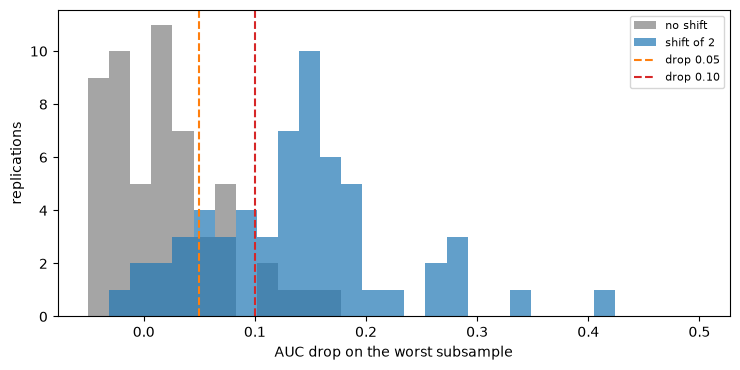

In [8]:
# Raw AUC drop of the worst subsample over 60 replications, without and with a planted shift
bins = np.linspace(-0.05, 0.5, 30)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(drop_samples[0.0], bins=bins, alpha=0.7, color="tab:gray", label="no shift")
ax.hist(drop_samples[2.0], bins=bins, alpha=0.7, color="tab:blue", label="shift of 2")
ax.axvline(0.05, color="tab:orange", linestyle="--", label="drop 0.05")
ax.axvline(0.10, color="tab:red", linestyle="--", label="drop 0.10")
ax.set_xlabel("AUC drop on the worst subsample")
ax.set_ylabel("replications")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Without a shift the drops are not centred on zero: their mean is 0.0119 and their 95th percentile 0.1203, so a good
share of them lies to the right of the 0.05 line (0.2000) and some beyond 0.10 (0.0833). With the planted shift the
histogram moves to a mean of 0.1348, and the fixed cuts detect it in 0.8500 and 0.6667 of the replications. The fixed cuts
therefore buy their power with false alarms, whereas the permutation rule keeps the false-alarm rate at 0.0667 and
detects the shift in 0.5000, at the price of a coarse reference with 39 draws.

### Step 3: the situation-testing light, at two cut points

The situation test returns, for the complainants of the protected group, how many are significant at level $\alpha = 0.05$ with the one-sided Wald interval of notebook 07. Even with no group effect some complainants are significant by chance, so the light reads the **share** of significant complainants against a cut point: green up to the cut, amber above, never red. A cut point is a convention, and the way to choose it is to measure the share's distribution under the null and under a planted bias. Two cells follow: one replication of 400 applicants, then 200 replications of 400 applicants drawn with the engine's threshold-bias plant at gap 0 (the null: the decision depends on the covariates only) and gap 0.8 (the protected group approved at a lower cut-off), runs the ceteris-paribus test with $k = 30$ and reports how often the share exceeds the first cut (0.10) and the second (0.20), the order of the two columns.

In [9]:
# One situation-testing replication with the threshold-bias plant at gap 0.8
draw = fair_plants.ThresholdBiasPlant(n=400, gap=0.8, seed=2000).draw_default()
result = situation.situation_test(draw["x"], draw["group"], draw["decision"], 30)
share = result.n_significant / result.n_complainants
print(f"complainants {result.n_complainants} | cases {result.n_cases}", end=" ")
print(f"| significant {result.n_significant} | share {share:.4f}")

complainants 218 | cases 186 | significant 167 | share 0.7661


The next cell repeats the test over 200 replications at gap 0 and gap 0.8 and counts how often the share crosses each cut.

In [10]:
# Share of significant complainants over 200 replications at gap 0 and gap 0.8, and how often it exceeds each cut
situation_rates = {}
print(f"{'gap':>5s} {'replications':>10s} {'mean share':>16s}", end=" ")
print(f"| {'share above 0.10':>24s} {'share above 0.20':>24s}")
for gap in (0.0, 0.8):
    shares = []
    for i in range(200):
        draw = fair_plants.ThresholdBiasPlant(n=400, gap=gap, seed=2000 + i).draw_default()
        result = situation.situation_test(draw["x"], draw["group"], draw["decision"], 30)
        shares.append(result.n_significant / result.n_complainants)
    shares = np.array(shares)
    situation_rates[gap] = ((shares > 0.10).mean(), (shares > 0.20).mean())
    print(f"{gap:5.1f} {len(shares):10d} {shares.mean():16.4f}", end=" ")
    print(f"| {situation_rates[gap][0]:24.4f} {situation_rates[gap][1]:24.4f}")

  gap replications       mean share |         share above 0.10         share above 0.20
  0.0        200           0.0398 |                   0.0850                   0.0150
  0.8        200           0.7338 |                   1.0000                   1.0000


## Comparison

The practice the research found for these three tests, with its gap:

- **Conformal coverage.** The dossier (C.7, l.1019 to 1028) prescribes the empirical coverage on out-of-time data against $1-\alpha$ "(binomial test on coverage indicators)". Angelopoulos and Bates (2021) and Vovk, Gammerman and Shafer (2022) give the guarantee $P(Y \in C(X)) \ge 1-\alpha$ under exchangeability; they do not describe the size of a validation test built on a finite calibration window. MAPIE and PiML (Reliability) implement the split form.
- **Resilience to shift.** PiML's Resilience test and the dossier (C.7, l.1013 to 1015) evaluate performance on the worst subsample by a shift score and on out-of-time windows; the dossier gives the construction and no rule for deciding that a drop is too large.
- **Situation testing.** Alvarez and Ruggieri (2025) give the statistic and the one-sided interval and leave the decision about how many significant complainants is too many to the user.

None of the toolkits of notebook 08 reports the rejection rates of these rules on data with a known truth.

## Evidence

What the product adds, claimed in the SDD: the three tests carry the corrections the engine's reviews decided, and the product shows, with the engine's own functions on planted data, the error rate each correction removes.

1. The coverage test reads the **Beta-Binomial** law of the covered count given the calibration size, and keeps the dossier's binomial p-value beside it.
2. The resilience light reads a **permutation reference** from the development rows (199 draws by default), not a fixed drop.
3. The situation-testing amber cut is **0.20**, the value that a size-and-power rule selects on one of the four designs that the measured-corrections paper measures; it costs power at small gaps and its size depends on the number of applicants, as the Summary states.

The committed rows show the corrected tests in use. The next cell prints the conformal windows of the Federal Reserve variant with both p-values, the resilience row with its draws and null summary, and the situation-testing row with the cut point it used.

In [11]:
# The committed corrected rows: both conformal p-values, the resilience draws and the situation-testing cut
for t in [t for t in fed["tests"] if t["test_id"] == "ml.conformal_coverage"]:
    x = t["extras"]
    print(f"{t['segment']:28s} n_cal {x['n_cal']} m {t['n']:6d} p Beta-Binomial {t['p_value']:.3g}", end=" ")
    print(f"| binomial {x['p_value_binomial']:.3g} | light {LIGHT[t['light']]}")
row = next(t for t in fed["tests"] if t["test_id"] == "ml.shift_resilience")
x = row["extras"]
print("resilience:", row["segment"], "| drop", round(row["metric"], 4), "| p", row["p_value"])
print("draws", x["shift_permutations"], "| null mean", round(x["null_mean"], 4), end=" ")
print("| null 95th percentile", round(x["null_p95"], 4), "|", LIGHT[row["light"]])
st = next(t for t in hmda["tests"] if t["test_id"] == "fair.situation_testing")
print("situation testing: share of significant complainants", round(st["metric"], 4))
print("cut points", st["extras"]["thresholds"]["amber"], "|", LIGHT[st["light"]])

window:baseline              n_cal 1471 m   3151 p Beta-Binomial 0.523 | binomial 0.313 | light green
window:fed-higher-risk-x0.25 n_cal 1471 m   3151 p Beta-Binomial 2.13e-35 | binomial 3.69e-127 | light red
window:fed-higher-risk-x0.5  n_cal 1471 m   3151 p Beta-Binomial 4.56e-52 | binomial 1.19e-194 | light red
window:fed-higher-risk-x1    n_cal 1471 m   3151 p Beta-Binomial 0.0372 | binomial 0.000258 | light amber
window:pooled                n_cal 1471 m  12604 p Beta-Binomial 2.86e-20 | binomial 2.16e-207 | light red
resilience: fed-higher-risk-x1 | drop 0.0857 | p 0.005
draws 199 | null mean 0.0007 | null 95th percentile 0.0243 | red
situation testing: share of significant complainants 0.2629
cut points 0.2 | amber


### The evidence, drawn

The last figure puts the false-alarm rate and the power of every rule side by side: the two fixed drop cuts and the
permutation reference of the resilience test, and the two amber cut points of the situation-testing light.

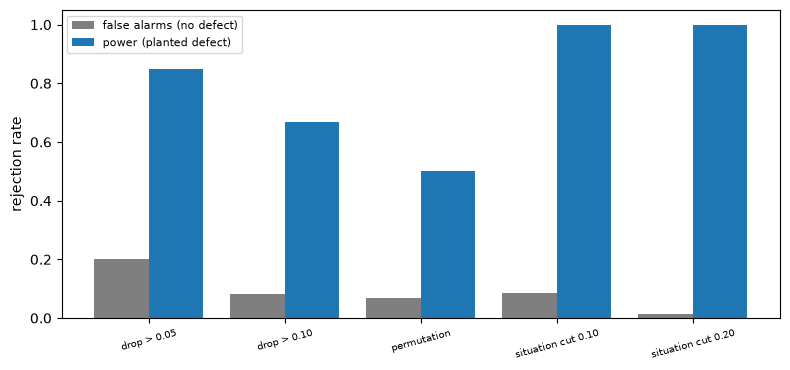

In [12]:
# False-alarm rate (grey) and power (blue) of the fixed and the corrected rules
names = ["drop > 0.05", "drop > 0.10", "permutation", "situation cut 0.10", "situation cut 0.20"]
null_rates = [*shift_rates[0.0][0], *situation_rates[0.0]]
power_rates = [*shift_rates[2.0][0], *situation_rates[0.8]]
index = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(index - 0.2, null_rates, width=0.4, color="tab:gray", label="false alarms (no defect)")
ax.bar(index + 0.2, power_rates, width=0.4, color="tab:blue", label="power (planted defect)")
ax.set_xticks(index)
ax.set_xticklabels(names, fontsize=7, rotation=15)
ax.set_ylabel("rejection rate")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In the grey bars the fixed drop cut 0.05 raises a false alarm in 0.2000 of the no-shift replications, the cut 0.10 in
0.0833, the permutation reference in 0.0667, the situation cut 0.10 in 0.0850 and the cut 0.20 in 0.0150. In the blue
bars the situation light detects the planted bias in every replication at both cuts (1.0000), and the resilience rules
detect the planted shift in 0.8500, 0.6667 and 0.5000. A good rule has a short grey bar and a tall blue one: the cut 0.20
is the only one that does both in this design and at the gap planted here (the paper's larger designs show a cost in power at smaller gaps), and the permutation reference trades power for size.

### Where the method changes or breaks

A measured size is a function of the design that measured it, and two parts of this notebook's design can be swept. The first is the **ratio of the test window to the calibration window** in the coverage test. The approximate size of the binomial null of step 1 says how fast it fails, and the Beta-Binomial null should hold at every ratio; the sweep takes eight ratios from 0.05 to 8 at a calibration window of 2,000, with 400 replications each, and prints the formula beside both measured sizes. The second is the **number of permutation draws** $R$ of the resilience test. A permutation p-value can never be smaller than

$$p_{\min} = \frac{1}{R + 1},$$

because the observed value is counted among the draws (Phipson and Smyth, 2010), so a rule that rejects at $p \le 0.05$ with $R = 19$ can only reject when no draw reaches the observed drop. The sweep takes $R$ of 19, 39 and 99 and measures, with 30 replications each, the false-alarm rate without shift and the power against a shift of 2.

The first sweep repeats the exchangeable replication 400 times at each of eight window ratios and prints the binomial size, the formula, the Beta-Binomial size and its Monte Carlo standard error.

In [13]:
# Sweep 1: the test window from 0.05 to 8 times the calibration window; measured sizes against the formula
import math


def binomial_size_formula(ratio):
    return 2 * (1 - 0.5 * (1 + math.erf(1.96 / math.sqrt(1 + ratio) / math.sqrt(2))))


ratio_rows = []
gen = np.random.default_rng(11)
n_cal_fixed = 2000
for ratio in (0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0):
    m_ratio = int(ratio * n_cal_fixed)
    below_b = below_bb = 0
    for _ in range(400):
        q_r = conformal.split_conformal_quantile(gen.random(n_cal_fixed), 0.1)
        sets_r = np.column_stack([gen.random(m_ratio) <= q_r, np.zeros(m_ratio, dtype=bool)])
        res_r = conformal.conformal_coverage(sets_r, np.zeros(m_ratio, dtype=int), 0.1, n_cal=n_cal_fixed)
        below_b += res_r.p_value_binomial < 0.05
        below_bb += res_r.p_value < 0.05
    size_bb = below_bb / 400
    se_bb = float(np.sqrt(size_bb * (1 - size_bb) / 400))
    ratio_rows.append((ratio, below_b / 400, binomial_size_formula(ratio), size_bb, se_bb))
print("m / n_cal   binomial size   formula   Beta-Binomial size   Monte Carlo se")
for ratio, size_b, formula, size_bb, se_r in ratio_rows:
    print(f"{ratio:9.2f} {size_b:15.4f} {formula:9.4f} {size_bb:20.4f} {se_r:14.4f}")

m / n_cal   binomial size   formula   Beta-Binomial size   Monte Carlo se
     0.05          0.0550    0.0558               0.0550         0.0114
     0.10          0.0550    0.0617               0.0325         0.0089
     0.25          0.0725    0.0796               0.0350         0.0092
     0.50          0.1000    0.1095               0.0475         0.0106
     1.00          0.1525    0.1658               0.0450         0.0104
     2.00          0.2675    0.2578               0.0425         0.0101
     4.00          0.3850    0.3807               0.0600         0.0119
     8.00          0.4750    0.5135               0.0425         0.0101


The second sweep runs the resilience rule at three numbers of draws, 30 replications at each shift, and prints the smallest attainable p-value, the false-alarm rate and the power.

In [14]:
# Sweep 2: the number of permutation draws (19, 39, 99); false alarms without shift, power with a shift of 2
import warnings

draw_rows = []
for draws in (19, 39, 99):
    rates_d = {}
    for shift in (0.0, 2.0):
        flagged, used = 0, 0
        for i in range(30):
            plant_d = plants.CovariateShiftPlant(n=600, shift=shift, features=[0], seed=3000 + i)
            d_d = plant_d.sample()
            x_e, y_e = d_d["X_eval"][:250], d_d["y_eval"][:250]
            score_d = robustness.shift_score_rank(d_d["X_dev"], x_e, seed=i)
            try:
                ref_d = robustness.shift_development_reference(
                    plant_d.predict, d_d["X_dev"], d_d["y_dev"], x_e, y_e, score_d, 0.25, draws, seed=i
                )
            except robustness.SingleClassSubsampleError:
                continue
            used += 1
            flagged += ref_d.p_value <= 0.05
        rates_d[shift] = (flagged / used, used)
    draw_rows.append((draws, 1 / (draws + 1), rates_d[0.0][0], rates_d[2.0][0], rates_d[0.0][1]))
print("draws   smallest p   size (shift 0)   power (shift 2)   replications")
for draws, p_min, size_d, power_d, used_d in draw_rows:
    print(f"{draws:11d} {p_min:11.4f} {size_d:20.4f} {power_d:23.4f} {used_d:10d}")

draws   smallest p   size (shift 0)   power (shift 2)   replications
         19      0.0500               0.0000                  0.4667         30
         39      0.0250               0.0000                  0.5000         30
         99      0.0100               0.0333                  0.5333         30


**Reading the tables.** The binomial size follows the formula within 0.0385 at every ratio: 0.0550 against 0.0558 at 0.05, 0.1525 against 0.1658 at 1 and 0.4750 against 0.5135 at 8, where it rejects almost one exchangeable window in two. The Beta-Binomial size stays between 0.0325 and 0.0600 at all eight ratios, never more than 2.0 Monte Carlo standard errors from the nominal 0.05, so the correction holds across ratios from 0.05 to 8, a span of 160, four times the span of step 1 (0.1 to 4). In the second table the smallest attainable p-value is 0.0500 at 19 draws, 0.0250 at 39 and 0.0100 at 99. The false-alarm rate is 0.0000, 0.0000 and 0.0333, at or under the nominal level each time, and the power is 0.4667, 0.5000 and 0.5333. With 30 replications the standard error of a rate near one half is about 0.09, so the rise in power with the number of draws is within the noise of this design; what the table does establish is that fewer draws never inflated the false alarms, and that at 19 draws the rule has no room to reject with a single exceedance.

The next cell draws both sweeps: on the left the measured sizes of the two nulls and the binomial formula against the window ratio on a logarithmic axis, with the nominal level; on the right the false-alarm rate and the power of the permutation rule against the number of draws.

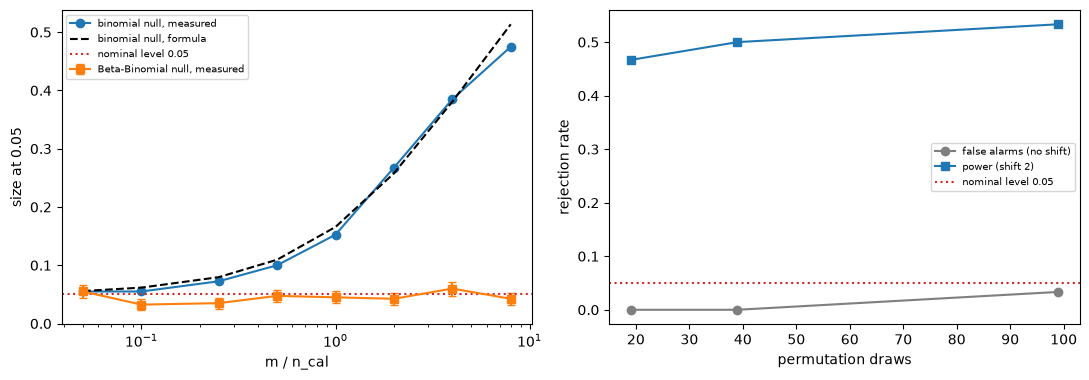

In [15]:
# Left: size of the coverage test against the window ratio; right: size and power against the permutation draws
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.9))
ratios = [r[0] for r in ratio_rows]
left.semilogx(ratios, [r[1] for r in ratio_rows], "o-", label="binomial null, measured")
left.semilogx(ratios, [r[2] for r in ratio_rows], "k--", label="binomial null, formula")
bb_size, bb_se = [r[3] for r in ratio_rows], [r[4] for r in ratio_rows]
left.errorbar(ratios, bb_size, yerr=bb_se, fmt="s-", capsize=3, label="Beta-Binomial null, measured")
left.axhline(0.05, color="tab:red", linestyle=":", label="nominal level 0.05")
left.set_xlabel("m / n_cal")
left.set_ylabel("size at 0.05")
left.legend(fontsize=7)
draws_axis = [r[0] for r in draw_rows]
right.plot(draws_axis, [r[2] for r in draw_rows], "o-", color="tab:gray", label="false alarms (no shift)")
right.plot(draws_axis, [r[3] for r in draw_rows], "s-", color="tab:blue", label="power (shift 2)")
right.axhline(0.05, color="tab:red", linestyle=":", label="nominal level 0.05")
right.set_xlabel("permutation draws")
right.set_ylabel("rejection rate")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

The left panel separates the two nulls cleanly: the binomial curve climbs along the formula as the test window outgrows the calibration window, and the Beta-Binomial points scatter around the dotted nominal line with error bars that reach it. The right panel is flat within its error: the grey false-alarm points stay near zero and the blue power points drift upward with wide uncertainty. What the figures do not show is a regime where the Beta-Binomial null fails: the exchangeable scores here are continuous and independent, and ties in the scores, or a calibration window that is not exchangeable with the test window, are outside this sweep and are the cases the committed coverage rows test.

### Using it on your own data

The protocol of this notebook applies to any rule of the engine, and it needs three things (contracts `engine-ml-api` and `engine-fairness-api`, the plants of `riskvalidation.ml.plants` and `riskvalidation.fairness.plants`):

1. **A plant with a known truth**: a generator with the defect off (the null) and on at a chosen severity, seeded, with a `truth()` that returns the exact value the rule estimates.
2. **A rule that returns a decision**: a boolean flag, a light, or a p-value against a level.
3. **Replications and their standard error**: the rejection rate over $R$ seeded draws and $\sqrt{\hat r(1-\hat r)/R}$; a rate with no error attached is not a measurement.

The next cell reads the contract of the rule measured below, the single-feature AUC screen of notebook 01 (`leakage.single_feature_auc`: its signature and units), and the signature of the plant it is measured on.

In [16]:
# Read the contract of the leak screen and the plant it is measured on, before measuring it
import inspect
import re

from riskvalidation.ml import leakage

ml_text = (ROOT / "docs" / "contracts" / "engine" / "ml-api.md").read_text(encoding="utf-8")
block = ml_text.split("### `riskvalidation.ml.leakage.single_feature_auc`")[1].split("###")[0]
for line in block.strip().splitlines():
    if line.startswith(("def ", "- Units", "- Invariants")):
        print(re.sub(r"\s+", " ", line)[:260])
print("signature of the plant:", inspect.signature(plants.LeakPlant))

def single_feature_auc(X: numpy.ndarray, y: numpy.ndarray, threshold: float = 0.95) -> SingleFeatureAuc
- Units: Returns the largest max(AUC, 1 - AUC) over columns, its column and whether it exceeds the near-perfect threshold (a convention); uses disc_auc.
- Invariants: Value in [0.5, 1].
signature of the plant: (n: 'int', leak_strength: 'float', seed: 'int') -> None


The call below measures that screen at three leak strengths with 300 replications of 2,000 obligors each: no leak, a strong leak and a near-perfect one. It also computes the leak strength at which the exact AUC of the leaking column reaches the screen's cut point of 0.95.

In [17]:
# A real call: size and power of the single-feature AUC screen of notebook 01 on the leak plant
import math
from statistics import NormalDist

strength_at_cut = math.sqrt(2) * NormalDist().inv_cdf(0.95)
print("leak strength whose exact AUC is 0.95:", round(strength_at_cut, 4))
print("leak strength   exact AUC   rejection rate   Monte Carlo se")
screen_rows = []
for strength in (0.0, 1.5, 3.0):
    hits, exact_auc = 0, None
    for i in range(300):
        plant_l = plants.LeakPlant(n=2000, leak_strength=strength, seed=5000 + i)
        draw_l = plant_l.sample()
        hits += bool(leakage.single_feature_auc(draw_l["X"], draw_l["y"]).suspect)
        exact_auc = plant_l.truth()["leak_auc"]
    rate_l = hits / 300
    se_l = float(np.sqrt(rate_l * (1 - rate_l) / 300))
    screen_rows.append((strength, exact_auc, rate_l, se_l))
    print(f"{strength:14.1f} {exact_auc:11.4f} {rate_l:15.4f} {se_l:15.4f}")

leak strength whose exact AUC is 0.95: 2.3262
leak strength   exact AUC   rejection rate   Monte Carlo se
           0.0      0.5000          0.0000          0.0000
           1.5      0.8556          0.0000          0.0000
           3.0      0.9831          1.0000          0.0000


**What to check in the output.** The rejection rate is 0.0000 without a leak (standard error 0.0000), 0.0000 at strength 1.5, where the leaking column has an exact AUC of 0.8556, and 1.0000 at strength 3, where it is 0.9831. The screen is a step function of the exact AUC: it never fires below the cut of 0.95 and always above it, and the strength where the exact AUC reaches 0.95 is 2.3262, between the two strengths measured. A leak that ranks the defaulters with an AUC of 0.8556 is far stronger than any honest column in notebook 01 (0.7454) and is still never flagged, so the power of this screen is a statement about the severity of the leak and not a constant. Check, for your own rule, that the null rate is under the nominal level with its standard error attached, that the power is reported at a severity a validator would care about, and that the plant's truth is used to say what the rule should have found.

## Results

**Answer:** Yes: the corrections remove most of the false alarms, at a cost in power for the permutation rule in this small design. With exchangeable data and a nominal level of 0.05, the binomial coverage test rejects in 0.1587 and 0.3893 of the replications when the test window equals or exceeds the calibration window, against 0.0440 and 0.0427 for the Beta-Binomial null. With no shift a fixed drop above 0.05 fires in 0.2000 of the replications and the permutation rule in 0.0667, while against a planted shift they detect it in 0.8500 and 0.5000. The situation cut 0.20 raises a false alarm in 0.0150 of the null replications against 0.0850 for the cut 0.10.

- **The binomial null makes the coverage test reject far too often once the test window is not small.** With exchangeable data and the nominal level 0.05, the binomial p-value falls below 0.05 in 0.0600 of the replications when the test window is a tenth of the calibration window (standard error 0.0061), in 0.1587 when the two windows are equal (0.0094) and in 0.3893 when the test window is four times the calibration window (0.0126). The Beta-Binomial p-value of the engine falls below 0.05 in 0.0460, 0.0440 and 0.0427 of them (standard errors from 0.0052 to 0.0054): below the nominal level at all three ratios, never above it. The committed Federal Reserve windows have a calibration window of 1,471 companies against test windows of 3,151 and 12,604, the regime where the two differ: the baseline window gives 0.523 (Beta-Binomial) and 0.313 (binomial), and for the 0.8800 coverage of the full shift the Beta-Binomial p-value is 0.0372 (amber) while the binomial one is 0.000258.
- **A fixed drop rule fires on a stable model; the permutation reference does not.** With no shift, the raw drop of the worst quarter by shift score has a mean of 0.0119 and a 95th percentile of 0.1203 over 60 replications. A rule "drop above 0.05" raises a false alarm in 0.2000 of them and "drop above 0.10" in 0.0833; the permutation rule (p at most 0.05, with 39 draws here) in 0.0667, which is within the standard error (0.0281) of the nominal level. Against the planted shift of 2 standard deviations the three rules detect it in 0.8500, 0.6667 and 0.5000 of the replications. So in this small design the permutation reference holds the false-alarm rate near its level and pays for it in power, because 250 evaluation rows and 39 draws make the reference coarse; the fixed cuts detect more because they also fire when there is nothing. The engine's default of 199 draws and larger samples narrow that cost, and this notebook does not measure it. The committed Federal Reserve row reads a drop of 0.0857 against a null that averages 0.0007 and has a 95th percentile of 0.0243 over 199 draws: p = 0.005, red.
- **The 0.20 cut point of the situation light removes most of the false alarms at no cost in power in this design.** With no group effect the share of significant complainants averages 0.0398, and exceeds the old cut 0.10 in 0.0850 of the 200 replications and the cut 0.20 in 0.0150; with the planted bias the share averages 0.7338 and exceeds both cuts in every replication. The engine's own documented measurement (a size of 0.039 at 0.20 and 0.194 at 0.10) uses another protocol and is not reproduced here: the direction agrees, the magnitude does not. The paper's larger designs qualify the claim: the cut 0.20 costs power at small gaps (0.410 against 0.743 for the cut 0.10 at a gap of 0.2) and its size depends on the number of applicants and on the data process (0.014 with 400 applicants and 0.035 on a second design; the cut 0.10 gives 0.114 at 400 and 0.018 at 1,000). The committed Delaware 2018 row has a share of 0.2629 against the cut 0.2: amber.
- **What this evidence supports for the claim.** The three corrections are in use in the committed documents (both conformal p-values side by side, 199 permutation draws, the cut 0.2), and the engine's own functions on planted data show the size each one corrects: 0.1587 and 0.3893 for the binomial coverage test against about 0.044 for the Beta-Binomial one, 0.2000 and 0.0833 for fixed drop cuts against 0.0667 for the permutation reference, 0.0850 against 0.0150 for the two situation cuts. All the committed rows were baked with riskvalidation 1.1.0.

What the results do not show: the simulations are small (1,500, 60 and 200 replications) and each rate carries the standard error printed beside it; the shift design has few rows and 39 draws; the engine's own size-and-power suites, which are larger, are in the engine's repository and are not run here; the planted defects are synthetic; and a test with a good size and power on a plant says nothing yet about a real portfolio.

## Summary

- The binomial null makes the coverage test reject in 0.0600, 0.1587 and 0.3893 of exchangeable replications at test-to-calibration ratios of 0.1, 1 and 4, while the Beta-Binomial null of the engine stays at 0.0460, 0.0440 and 0.0427.
- A fixed AUC-drop rule on the worst subsample raises a false alarm in 0.2000 and 0.0833 of no-shift replications; the permutation reference in 0.0667, at a cost in power in this small design.
- The situation-testing amber cut 0.20 raises a false alarm in 0.0150 of null replications against 0.0850 for the cut 0.10, and both detect the planted bias in every replication at the gap planted here (0.8). The measured-corrections paper, with larger designs, qualifies the cut 0.20: it costs power at small gaps (0.410 against 0.743 for the cut 0.10 at a gap of 0.2, 0.968 against 1.000 at 0.4), and its size depends on the applicants and the data process (0.014 with 400 applicants, 0.035 on a second design with independent attributes, where the cut 0.10 gives 0.114 and 0.195, and 0.018 for the cut 0.10 with 1,000 applicants). Three of the paper's ten predictions are refuted, and half of them were formulated with the experiments, not before.
- The committed C20 and C21 rows carry the corrections in use: both conformal p-values side by side, 199 permutation draws and the cut 0.2, baked with riskvalidation 1.1.0.
- Each rate is printed with its Monte Carlo standard error; the simulations are small, the plants synthetic, and the engine's larger size-and-power suites are not run here.

**What to try next.** Topic 14 measures the size and the power of the engine's whole catalogue on planted defects, with the same method at a larger scale.

## References

- Angelopoulos, A. N. and Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- PiML-Toolbox (Apache-2.0), outcome tests WeakSpot, Overfit, Reliability, Robustness and Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- Phipson, B. and Smyth, G. K. (2010), Permutation p-values should never be zero, Statistical Applications in Genetics and Molecular Biology 9(1). https://doi.org/10.2202/1544-6115.1585
- ECB (2025), Guide to internal models, the paragraphs on the randomness of the training process, overfitting, explainability and the justification of complexity (43, 59, 60, 62, 64 to 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Alvarez, J. M. and Ruggieri, S. (2025), Counterfactual situation testing: from single to multidimensional discrimination, Journal of Artificial Intelligence Research 82, arXiv 2502.01267. https://doi.org/10.1613/jair.1.17935
- Zieba, M., Tomczak, S. K. and Tomczak, J. M., Polish companies bankruptcy data, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data